In [51]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print(os.getcwd())

C:\Users\Steven Tsoukalas\Documents\nyc-building-energy


In [52]:
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.model_selection import GroupKFold, KFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from lightgbm import LGBMRegressor

feat = gpd.read_parquet("data/clean/features.parquet")
feat["log_eui"] = np.log(feat["site_eui"])

# drop buildings where LL84 and MapPLUTO disagree on floor area by more than 2x
ratio = feat["gfa"] / feat["bldgarea"]
bad = ~ratio.between(0.5, 2)
print(f"Floor areas differ by more than 2x: {bad.sum()} of {len(feat)}")
feat = feat[~bad].copy()

feat[["numfloors", "unitsres"]] = feat[["numfloors", "unitsres"]].replace(0, np.nan)   # 0 means unknown in MapPLUTO
feat["age"] = 2024 - feat["year_built"]
feat["log_gfa"] = np.log(feat["bldgarea"])   # size from MapPLUTO, independent of EUI's denominator
feat["gfa_per_unit"] = feat["bldgarea"].replace(0, np.nan) / feat["unitsres"].replace(0, np.nan)   # both from MapPLUTO
feat.loc[~feat["gfa_per_unit"].between(200, 5000), "gfa_per_unit"] = np.nan   # implausible → unknown
feat["bldgclass"] = feat["bldgclass"].astype("category")
feat["borough"] = feat["borough"].replace("STATEN ISLAND", "STATEN IS")
feat["borough"] = feat["borough"].astype("category")

features = ["age", "log_gfa", "numfloors", "unitsres", "gfa_per_unit",
            "bldgclass", "borough", "n_lots_500m", "median_year_500m", "avg_floors_500m"]
X, y = feat[features], feat["log_eui"]
groups = feat["zip"]

Floor areas differ by more than 2x: 89 of 14628


In [53]:
spatial_cv = GroupKFold(n_splits=5)
random_cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [54]:
X_lin = pd.get_dummies(X, drop_first=True).fillna(X.median(numeric_only=True))
lin_r2 = cross_val_score(LinearRegression(), X_lin, y, cv=spatial_cv,
                         groups=groups, scoring="r2")
print(f"Linear R²: {lin_r2.mean():.3f} ± {lin_r2.std():.3f}")

Linear R²: 0.061 ± 0.013


In [55]:
model = LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31,
                      min_child_samples=30, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, verbose=-1)

r2_spatial = cross_val_score(model, X, y, cv=spatial_cv, groups=groups, scoring="r2")
r2_random = cross_val_score(model, X, y, cv=random_cv, scoring="r2")
print(f"LightGBM R², spatial split: {r2_spatial.mean():.3f}")
print(f"LightGBM R², random split:  {r2_random.mean():.3f}")

LightGBM R², spatial split: 0.099
LightGBM R², random split:  0.125


model still does well on unseen zipcodes

In [56]:
pred_log = cross_val_predict(model, X, y, cv=spatial_cv, groups=groups)
feat["pred_eui"] = np.exp(pred_log)
mae = mean_absolute_error(feat["site_eui"], feat["pred_eui"])
print(f"Average error: {mae:.1f} kBtu/ft² (median EUI is {feat['site_eui'].median():.0f})")

Average error: 21.0 kBtu/ft² (median EUI is 72)


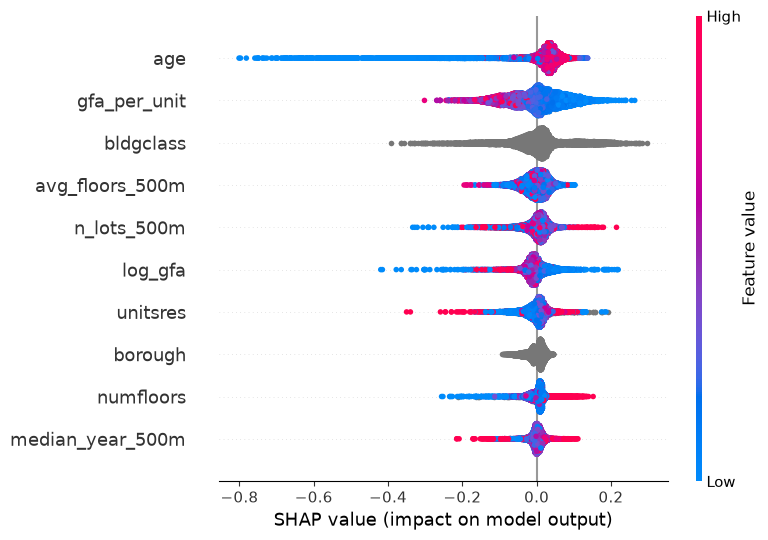

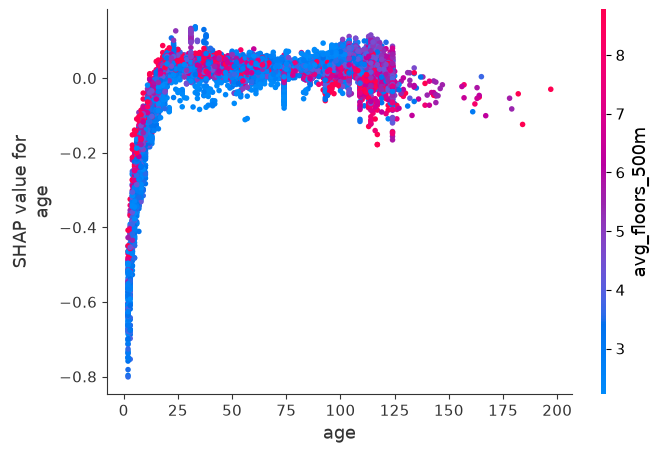

In [57]:
import shap

model.fit(X, y)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)
shap.summary_plot(shap_values, X)                       # overall importance and direction
shap.dependence_plot("age", shap_values, X)             # how age affects predictions

In [58]:
naive = np.full(len(feat), feat["site_eui"].median())
print(f"Guessing the median: {mean_absolute_error(feat['site_eui'], naive):.1f} kBtu/ft²")
print(f"LightGBM:            {mae:.1f} kBtu/ft²")

Guessing the median: 22.9 kBtu/ft²
LightGBM:            21.0 kBtu/ft²


In [59]:
cols = ["bbl", "gfa", "unitsres", "units", "gfa_per_unit", "site_eui"]
print(feat.nsmallest(15, "gfa_per_unit")[cols])

              bbl       gfa  unitsres  units  gfa_per_unit  site_eui
4041   1018870048   26834.0     108.0   97.0    248.462963      92.9
4609   1020890029   25091.0      94.0   92.0    266.925532     139.5
392    1003870124   11418.0      40.0   40.0    285.450000     175.1
3691   1017220022   25871.0      90.0   90.0    287.455556      98.1
4515   1020680067   40681.0     117.0  119.0    288.512821     180.2
2363   1012520027   32482.0     109.0  109.0    290.733945      94.1
3419   1015490014   10500.0      28.0   28.0    302.321429     121.8
1385   1008790027  101000.0     326.0  326.0    312.444785      75.8
1631   1010150001  225464.0     652.0  650.0    324.334356     133.7
13790  4036440030   34603.0      92.0   42.0    339.130435      71.2
10221  3031130032   52650.0     153.0   66.0    344.117647      74.4
10946  3051010090   23478.0      62.0   62.0    352.258065     105.8
4103   1018950023  104292.0     250.0   47.0    353.328000     177.7
2175   1012170057   72000.0     20

In [60]:
building = ["age", "log_gfa", "numfloors", "unitsres", "gfa_per_unit", "bldgclass"]
location = ["borough", "n_lots_500m", "median_year_500m", "avg_floors_500m"]
y, groups = feat["log_eui"], feat["zip"]

for name, cols in [("building only", building),
                   ("location only", location),
                   ("both", building + location)]:
    r2 = cross_val_score(model, feat[cols], y, cv=spatial_cv, groups=groups, scoring="r2").mean()
    print(f"{name:15s} R² = {r2:.3f}")

building only   R² = 0.093
location only   R² = -0.023
both            R² = 0.099


In [61]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, classification_report

feat["low_perf"] = (feat["site_eui"] > feat["site_eui"].quantile(0.75)).astype(int)

clf = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=31, verbose=-1)
proba = cross_val_predict(clf, X, feat["low_perf"], cv=spatial_cv,
                          groups=groups, method="predict_proba")[:, 1]
feat["p_low"] = proba
print(f"AUC: {roc_auc_score(feat['low_perf'], proba):.3f}")
print(classification_report(feat["low_perf"], proba > 0.5))

AUC: 0.752
              precision    recall  f1-score   support

           0       0.80      0.93      0.86     10908
           1       0.57      0.29      0.39      3631

    accuracy                           0.77     14539
   macro avg       0.68      0.61      0.62     14539
weighted avg       0.74      0.77      0.74     14539



In [62]:
feat["excess_pct"] = (feat["site_eui"] / feat["pred_eui"] - 1) * 100
feat["flag"] = feat["excess_pct"] > 50
print(feat["flag"].sum())
print(feat.groupby("borough", observed=True)["flag"].agg(["mean", "count"]))

1855
               mean  count
borough                   
BRONX      0.143076   3264
BROOKLYN   0.113917   3801
MANHATTAN  0.129104   5391
QUEENS     0.119581   2007
STATEN IS  0.250000     76


In [63]:
import os
os.makedirs("docs", exist_ok=True)

m = feat.copy()
m["geometry"] = m.geometry.centroid      # in feet (EPSG:2263), so centroids are accurate
m = m.to_crs(4326)                        # then to latitude/longitude for the web map
m["excess_pct"] = m["excess_pct"].round(0)
m["pred_eui"] = m["pred_eui"].round(0)

cols = ["bbl", "borough", "year_built", "site_eui", "pred_eui", "excess_pct", "flag", "geometry"]
web_map = m[cols].explore(
    column="excess_pct", cmap="RdYlBu_r", vmin=-50, vmax=50,
    tooltip=["bbl", "year_built", "site_eui", "pred_eui", "excess_pct"],
    marker_kwds={"radius": 4}, tiles="Esri.WorldGrayCanvas",
    legend_kwds={"caption": "% above (red) or below (blue) predicted energy use"},
)
web_map.save("docs/index.html")

In [64]:
top = feat.nlargest(500, "p_low")
print(f"Of the 500 highest-risk buildings, {top['low_perf'].mean():.0%} are true low performers (vs 25% at random)")

Of the 500 highest-risk buildings, 61% are true low performers (vs 25% at random)


In [65]:
cols = ["bbl", "borough", "year_built", "gfa", "bldgarea", "unitsres",
        "site_eui", "pred_eui", "excess_pct", "lat", "lon"]
extreme = feat.nlargest(10, "excess_pct")[cols]

raw = pd.read_csv("data/raw/ll84.csv", low_memory=False,
                  usecols=["NYC Borough, Block and Lot (BBL)", "Calendar Year", "Address 1", "Property Name"])
raw = raw[raw["Calendar Year"] == 2024]
raw["bbl"] = pd.to_numeric(raw["NYC Borough, Block and Lot (BBL)"], errors="coerce").astype("Int64")
extreme = extreme.merge(raw[["bbl", "Address 1", "Property Name"]], on="bbl", how="left")
extreme

,bbl,borough,year_built,gfa,bldgarea,unitsres,site_eui,pred_eui,excess_pct,lat,lon,Address 1,Property Name
0,2024430170,BRONX,1963,876498.0,876500,936.0,249.0,41.357490,502.067486,40.823032,-73.919872,773 Concourse Village East,773-779 Concourse Village
1,3022647519,BROOKLYN,2018,31301.0,31066,10.0,245.8,49.238450,399.203363,40.700160,-73.953267,242 Wallabout Street,242 Wallabout
2,2023040001,BRONX,1965,670550.0,550000,642.0,227.2,45.544532,398.852416,40.811292,-73.922115,388 EAST 141ST STREET,Mott Haven - Bldgs 2-6
3,2037250001,BRONX,1955,559670.0,525346,534.0,218.5,45.768159,377.406135,40.827480,-73.867747,1744 Watson AVENUE,"Sotomayor Houses - Bldgs 12-21, 29-31"
4,1021720032,MANHATTAN,1916,42135.0,41140,18.0,229.4,52.161109,339.791267,40.861967,-73.930034,4646-48 Broadway,4646 Broadway LLC
5,3002380035,BROOKLYN,1971,233922.0,212656,121.0,220.3,52.303876,321.192492,40.695835,-73.991673,10 CLINTON STREET,10 CLINTON STREET - Cadman Towers
6,4031040023,QUEENS,1950,37623.0,75246,84.0,197.1,46.971311,319.617842,40.727171,-73.863548,63-70 Austin St,Pinnacle CHILD - 63-70 Austin Street
7,4031040023,QUEENS,1950,37623.0,75246,84.0,197.1,46.971311,319.617842,40.727171,-73.863548,63-70 Austin Street,Pinnacle PARENT - 63-70 Austin Street / 63-90 ...
8,4031040023,QUEENS,1950,37623.0,75246,84.0,197.1,46.971311,319.617842,40.727171,-73.863548,63-90 Austin Street,Pinnacle CHILD - 63-90 Austin Street
9,2030500020,BRONX,1910,14900.0,16300,20.0,152.6,36.874586,313.835152,40.854880,-73.893438,2268 Washington Avenue,2268 Washington Avenue


In [66]:
print(feat["site_eui"].quantile([0.5, 0.9, 0.95, 0.99]).round(0))

0.50     72.0
0.90    109.0
0.95    126.0
0.99    173.0
Name: site_eui, dtype: float64
